## Community Structure

### E.1 What is a Community?

A **community** (or cluster) is a group of nodes that are **more densely connected to each other than to the rest of the graph**.

**Key distinction:** A community is different from a connected component:
- **Connected component:** A group where every node can reach every other node (hard boundary).
- **Community:** A group where internal connections are denser than external ones (soft boundary, depends on the algorithm).

**Important warning:** Community detection is **not deterministic** — different algorithms may produce different (but equally valid) communities. Communities are a useful model, not an objective truth.

### E.2 Modularity

**Modularity** measures how good a community partition is. It compares the actual density of edges *within* communities to the expected density if edges were placed randomly.

- **Q close to 1.0:** Very strong community structure.
- **Q close to 0.0:** No community structure (random graph).
- **Q negative:** Fewer within-community edges than expected by chance.

In [1]:
import networkx as nx
import matplotlib.pyplot as plt
K = nx.Graph()
# Left cluster (tightly connected)
K.add_edges_from([("A", "B"), ("A", "C"), ("A", "D"),
                  ("B", "C"), ("B", "D"), ("C", "D")])
# Right cluster (tightly connected)
K.add_edges_from([("E", "F"), ("E", "G"), ("E", "H"),
                  ("F", "G"), ("F", "H"), ("G", "H")])
# Bridge between clusters
K.add_edge("D", "E")

## Greedy Modularity

In [2]:
# ─────────────────────────────────────────────────────────────────────────────
# COMMUNITY DETECTION using Greedy Modularity
# ─────────────────────────────────────────────────────────────────────────────
from networkx.algorithms.community import greedy_modularity_communities, modularity

# Use the two-cluster graph K from the clustering section
communities = list(greedy_modularity_communities(K))

print("=" * 55)
print("COMMUNITY DETECTION — Greedy Modularity")
print("=" * 55)
print(f"Number of communities detected: {len(communities)}")

for i, community in enumerate(communities, 1):
    print(f"  Community {i}: {sorted(community)}")

# Compute modularity score
Q = modularity(K, communities)
print(f"\nModularity score (Q): {Q:.4f}")
print("A value near 0.5 indicates moderately strong community structure.")

COMMUNITY DETECTION — Greedy Modularity
Number of communities detected: 2
  Community 1: ['A', 'B', 'C', 'D']
  Community 2: ['E', 'F', 'G', 'H']

Modularity score (Q): 0.4231
A value near 0.5 indicates moderately strong community structure.


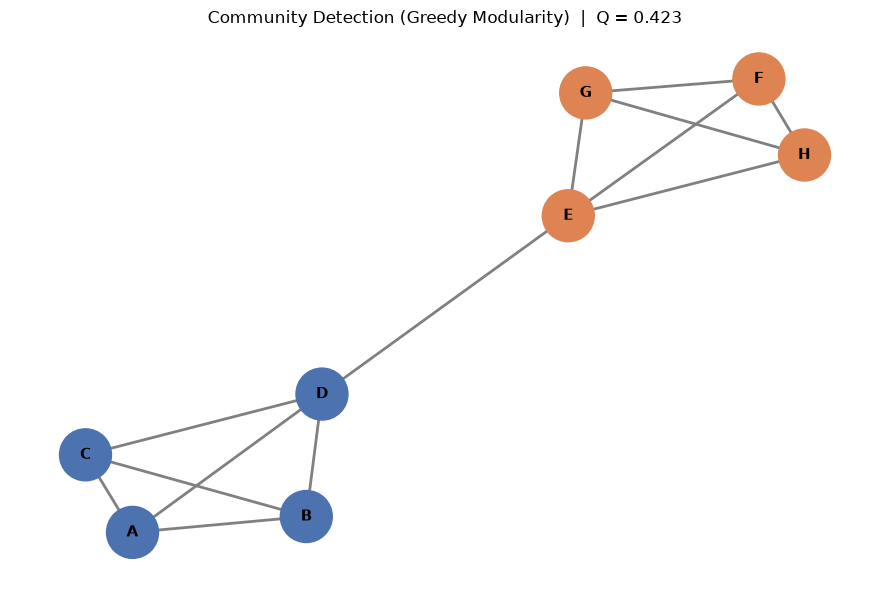

In [3]:
plt.figure(figsize=(9, 6))
pos = nx.spring_layout(K, seed=99)

palette = ["#4C72B0", "#DD8452", "#55A868", "#C44E52"]
node_color_map = {}
for i, community in enumerate(communities):
    for node in community:
        node_color_map[node] = palette[i % len(palette)]

colors = [node_color_map[n] for n in K.nodes()]

nx.draw_networkx(
    K, pos,
    node_color=colors,
    node_size=1400,
    font_size=11,
    font_weight="bold",
    edge_color="gray",
    width=2,
)

plt.title(f"Community Detection (Greedy Modularity)  |  Q = {Q:.3f}", fontsize=12)
plt.axis("off")
plt.tight_layout()
plt.show()